# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [6]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [7]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [8]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [9]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1) #display attention scores in good way

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [10]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

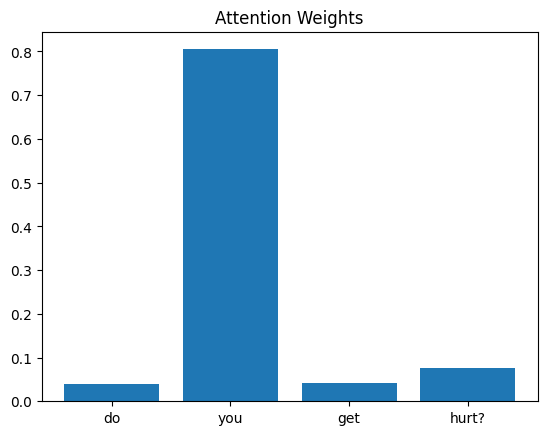

In [11]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Q123: so how should i refer to you?
   Highest word: should (0.559)   Predicted: 8   True: 8
Q164: that was a clever answer
   Highest word: answer (0.904)   Predicted: 11   True: 11
Q86: i'm curious about your family
   Highest word: family (0.912)   Predicted: 6   True: 6


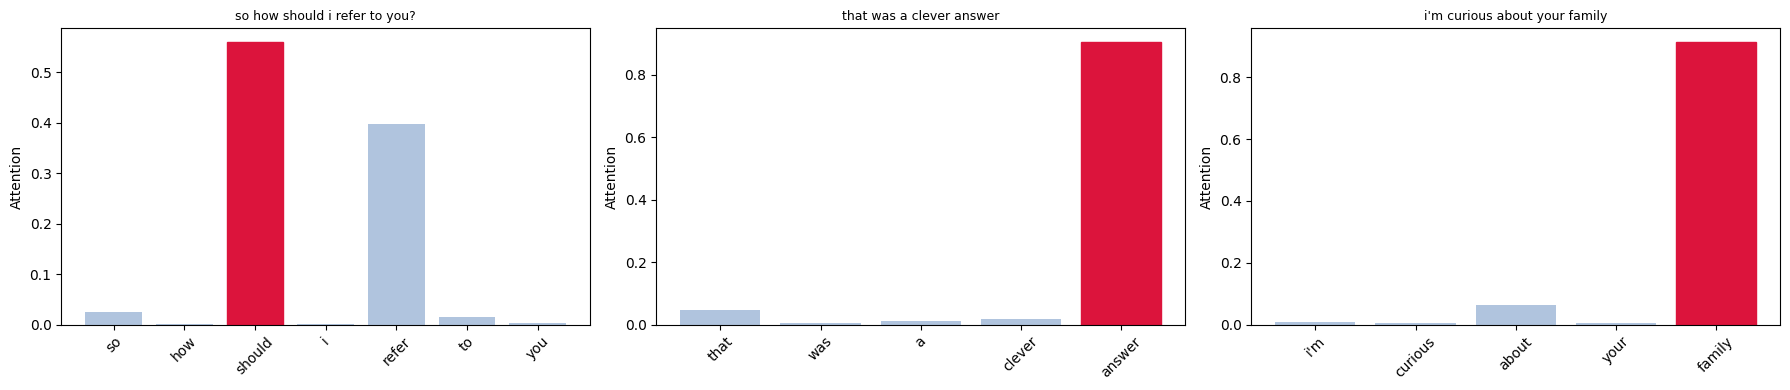

In [12]:
def get_attention(i):
    words = [tokenizer.index_word[t] for t in X[i].tolist() if t != 0]
    with torch.no_grad():
        prediction, weights = model(X[i:i+1])
    w = weights[0, :len(words)].tolist()
    return words, w, prediction.argmax(1).item()

def plot_attention(i, ax):
    words, w, pred = get_attention(i)
    top = words[w.index(max(w))]
    bars = ax.bar(range(len(words)), w, color="lightsteelblue")
    bars[w.index(max(w))].set_color("crimson")
    ax.set_xticks(range(len(words)))
    ax.set_xticklabels(words, rotation=45)
    ax.set_title(df["question"][i], fontsize=9)
    ax.set_ylabel("Attention")
    return top, max(w), pred

idx = df.sample(3, random_state=7).index.tolist()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, i in zip(axes, idx):
    top, score, pred = plot_attention(i, ax)
    print(f"Q{i}: {df['question'][i]}")
    print(f"   Highest word: {top} ({score:.3f})   Predicted: {pred}   True: {y[i].item()}")
plt.tight_layout()
plt.show()

**Ans:** Mostly yes. Family got 0.912 and answer got 0.904 and both are the main topic of their questions. In the first question should got the top weight with 0.559 instead of refer so attention does not always pick the word a person would pick but all three answers were still right

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Q0: do you get hurt?
   Top 3 words: ['you', 'hurt', 'get']   Predicted: 0   True: 0
Q1: do you have fingers?
   Top 3 words: ['you', 'fingers', 'do']   Predicted: 0   True: 0


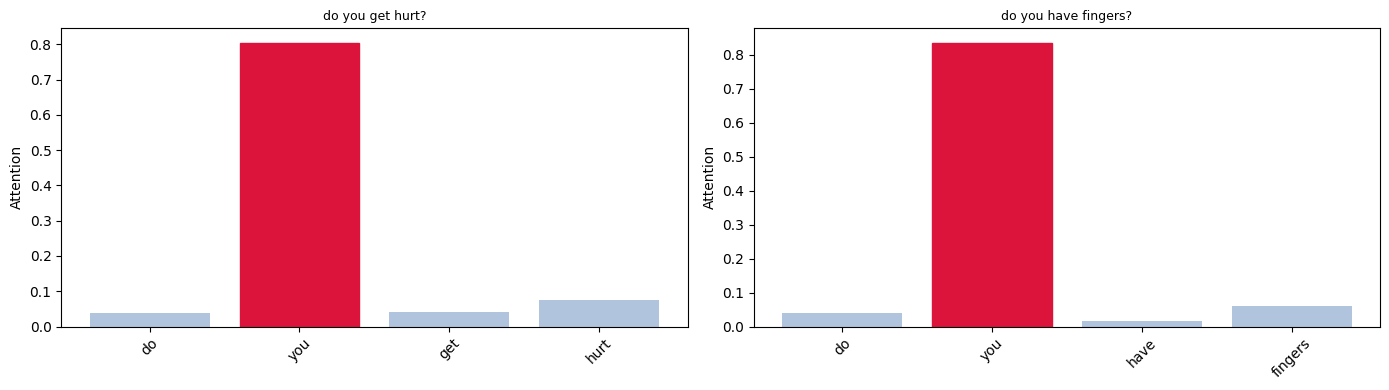

Shared top words: {'you'}


In [13]:
counts = df["answer_id"].value_counts()
group = counts[counts >= 2].index[0]
pair = df[df["answer_id"] == group].index[:2].tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
top_words = []
for ax, i in zip(axes, pair):
    plot_attention(i, ax)
    words, w, pred = get_attention(i)
    order = sorted(range(len(w)), key=lambda j: w[j], reverse=True)[:3]
    top_words.append([words[j] for j in order])
    print(f"Q{i}: {df['question'][i]}")
    print(f"   Top 3 words: {top_words[-1]}   Predicted: {pred}   True: {y[i].item()}")
plt.tight_layout()
plt.show()

shared = set(top_words[0]) & set(top_words[1])
print("Shared top words:", shared if shared else "none")

**Ans:** Both questions focused on you then each one focused on its own word like hurt and fingers and both were predicted as group 0. This shows attention does not understand meaning it just picks the words that helped the model reach the right answer during training